# EVALUACION ESTRATEGIAS

In [6]:
import pandas as pd
results = pd.read_csv('outputs/resultados/resultados_experimentos.csv')
results

,Retrieval,Ranker,Recall_Retrieval_Promedio,NDCG@20_Promedio,Tiempo_Segundos
0,Q1_Populares,Popularidad,0.039417,0.010018,1.84
1,Q1_Populares,Jaccard,0.039417,0.007020,2.06
2,Q1_Populares,CF_DotProduct,0.039417,0.006155,2.92
3,Q1_Populares,CF_Promedio,0.039417,0.007142,6.20
4,Q1_Populares,EASE_Ranker,0.039417,0.008625,10.35
5,Q2_Mismo_Autor,Popularidad,0.015522,0.005294,2.43
6,Q2_Mismo_Autor,Jaccard,0.015522,0.005554,2.51
7,Q2_Mismo_Autor,CF_DotProduct,0.015522,0.004997,3.00
8,Q2_Mismo_Autor,CF_Promedio,0.015522,0.004627,5.18
9,Q2_Mismo_Autor,EASE_Ranker,0.015522,0.007244,11.72


In [7]:
df_test=pd.read_parquet('outputs/datasets/df_test.parquet')
df_test.shape

(10630, 4)

In [8]:
len(list(df_test.id_lector.unique()))

1063

In [9]:
id_lectores =pd.DataFrame({'id_lector':df_test.id_lector.unique()})

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
estrategias_retrieval = ["Q1_Populares","Q2_Mismo_Autor",
                         "Q3_Mismo_Genero","Q4_Popularidad_Pais",
                         "Q5_Trending","Hibrido","Q6_Productos_Asociados","Q7_EASE"]
estrategias_ranker = ["Popularidad" ,"Jaccard","CF_DotProduct",
                      "CF_Promedio","EASE_Ranker"]
df_resultados = pd.DataFrame({'id_lector':df_test.id_lector.unique()})
for ret in estrategias_retrieval:
    for rank in estrategias_ranker:
        ckpt_i = pd.read_csv(f'outputs/checkpoints/ckpt_{ret}_{rank}.csv')
        ckpt_i = ckpt_i.rename(columns={'recall':f'recall_{ret}_{rank}' , 'ndcg':f'ndcg_{ret}_{rank}'})
        print(f'retrieval:{ret} - ranker : {rank}')
        print(ckpt_i.shape)
        df_resultados = df_resultados.merge(ckpt_i , on='id_lector',how='inner')
    
    

retrieval:Q1_Populares - ranker : Popularidad
(1063, 3)
retrieval:Q1_Populares - ranker : Jaccard
(1063, 3)
retrieval:Q1_Populares - ranker : CF_DotProduct
(1063, 3)
retrieval:Q1_Populares - ranker : CF_Promedio
(1063, 3)
retrieval:Q1_Populares - ranker : EASE_Ranker
(1063, 3)
retrieval:Q2_Mismo_Autor - ranker : Popularidad
(1063, 3)
retrieval:Q2_Mismo_Autor - ranker : Jaccard
(1063, 3)
retrieval:Q2_Mismo_Autor - ranker : CF_DotProduct
(1063, 3)
retrieval:Q2_Mismo_Autor - ranker : CF_Promedio
(1063, 3)
retrieval:Q2_Mismo_Autor - ranker : EASE_Ranker
(1063, 3)
retrieval:Q3_Mismo_Genero - ranker : Popularidad
(1063, 3)
retrieval:Q3_Mismo_Genero - ranker : Jaccard
(1063, 3)
retrieval:Q3_Mismo_Genero - ranker : CF_DotProduct
(1063, 3)
retrieval:Q3_Mismo_Genero - ranker : CF_Promedio
(1063, 3)
retrieval:Q3_Mismo_Genero - ranker : EASE_Ranker
(1063, 3)
retrieval:Q4_Popularidad_Pais - ranker : Popularidad
(1063, 3)
retrieval:Q4_Popularidad_Pais - ranker : Jaccard
(1063, 3)
retrieval:Q4_Popula

In [11]:
df_train_feat = pd.read_parquet('outputs/datasets/df_train_features.parquet')
print(df_train_feat.shape)
df_train_feat.head()

(32360, 30)


,id_lector,id_libro,rating,fecha_interaccion,titulo,autor,genero_libro,anio_edicion,rating_promedio,cantidad_votos,...,genero_favorito_por_lector,ratio_libros_antiguos_vs_nuevos_por_lector,rating_promedio_te_por_lector,pct_autor_favorito_por_lector,pct_genero_favorito_por_lector,popularidad_count_por_libro,popularidad_rating_mean_por_libro,rating_promedio_te_por_libro,pct_lecturas_autor_candidato_por_par_libroylector,pct_lecturas_genero_candidato_por_par_libroylector
0,0Pharaoh,88502.0,10.0,2025-12-26,The Stellar Swordmaster,,Action,2023.0,4.375,2112.0,...,Action,0.0,6.8112,0.333333,1.00,12,9.083333,7.2337,0.3333,1.00
1,0Pharaoh,78077.0,7.5,2025-12-29,The Infinite Mage,Themis,Action,2022.0,4.186,3244.0,...,Action,0.0,6.8112,0.333333,1.00,14,7.385714,6.9202,0.3333,1.00
2,0Pharaoh,111112.0,4.0,2026-05-02,House Mayton's Youngest - Part 4,Vichu,Action,2025.0,3.777,62.0,...,Action,0.0,6.8112,0.333333,1.00,1,4.000000,6.7351,0.3333,1.00
3,135dragon,53482.0,9.0,2021-02-12,My Dad Is Too Strong,Gaebyeok S,Action,2020.0,4.001,1902.0,...,Action,0.0,7.1532,0.040000,0.92,10,6.360000,6.7182,0.0400,0.92
4,135dragon,23973.0,8.0,2021-02-13,Black Summoner,Gin AMOU,Action,2018.0,3.943,1737.0,...,Action,0.0,7.1532,0.040000,0.92,6,6.666667,6.7766,0.0400,0.92


In [12]:
cols_por_lector = [c for c in df_train_feat.columns if 'por_lector' in c]
cols_por_lector

['volumen_lectura_por_lector',
 'rating_promedio_crudo_por_lector',
 'desviacion_estandar_rating_por_lector',
 'genero_favorito_por_lector',
 'ratio_libros_antiguos_vs_nuevos_por_lector',
 'rating_promedio_te_por_lector',
 'pct_autor_favorito_por_lector',
 'pct_genero_favorito_por_lector']

In [13]:
df_caract_lector = df_train_feat.groupby('id_lector').agg(
    volumen_lectura_por_lector = ('volumen_lectura_por_lector','max'),
    rating_promedio_crudo_por_lector = ('rating_promedio_crudo_por_lector','max'),
    desviacion_estandar_rating_por_lector = ('desviacion_estandar_rating_por_lector','max'),
    genero_favorito_por_lector = ('genero_favorito_por_lector','max'),
    ratio_libros_antiguos_vs_nuevos_por_lector = ('ratio_libros_antiguos_vs_nuevos_por_lector','max'),
    rating_promedio_te_por_lector = ('rating_promedio_te_por_lector','max'),
    pct_autor_favorito_por_lector = ('pct_autor_favorito_por_lector','max'),
    pct_genero_favorito_por_lector = ('pct_genero_favorito_por_lector','max'),
)
df_caract_lector.shape

(967, 8)

In [14]:
df_analisis = df_resultados.merge(df_caract_lector ,on='id_lector',how='left')
df_analisis=df_analisis.fillna(0)
print(df_analisis.shape)
print(df_analisis.isna().sum().sum())

(1063, 89)
0


In [15]:
import numpy as np

cols_ndcg = [c for c in df_analisis.columns if 'ndcg' in c]
cols_por_lector = [c for c in df_analisis.columns if 'por_lector' in c and c not in ['rating_promedio_crudo_por_lector',
                                                                                     'desviacion_estandar_rating_por_lector',
                                                                                        'genero_favorito_por_lector']]
states = {}

for col in cols_por_lector:
    print("*"*30 + f" {col}")
    
    activos = df_analisis.loc[df_analisis[col] > 0, col]
    
    # Por las dudas, si alguna columna no tiene valores mayores a 0, la saltamos
    if activos.empty:
        continue
        
    limites_activos = activos.quantile(np.linspace(0, 1, 6)).tolist()
    
    cortes = [-1, 0] + limites_activos[1:]
    cortes = sorted(list(set(cortes)))
    
    etiquetas = ['0 (Cold-Start)']
    
    for max_val in cortes[2:]:
        # CAMBIO 1: Usamos round(max_val, 2) en lugar de int() para aceptar decimales
        etiquetas.append(f'<= {round(max_val, 2)}')
        
    df_analisis[f"{col}_RANGOS"] = pd.cut(
        df_analisis[col], 
        bins=cortes, 
        labels=etiquetas
    )
    print(df_analisis[f"{col}_RANGOS"].value_counts(sort=False))
    
    agregaciones = {
        'cantidad_lectores': ('id_lector', 'count')
    }

    for col2 in cols_ndcg:
        # CAMBIO 2: Cambié 'col' por 'col2' para que calcule la media del NDCG
        agregaciones[f'{col2}_mean'] = (col2, 'mean') 

    # Agrupamos (usamos observed=False para evitar warnings futuros de Pandas con variables categóricas)
    states[col] = df_analisis.groupby(f"{col}_RANGOS", observed=False).agg(**agregaciones)

****************************** volumen_lectura_por_lector
volumen_lectura_por_lector_RANGOS
0 (Cold-Start)     96
<= 3.0            216
<= 7.0            186
<= 15.0           181
<= 35.0           191
<= 2569.0         193
Name: count, dtype: int64
****************************** ratio_libros_antiguos_vs_nuevos_por_lector
ratio_libros_antiguos_vs_nuevos_por_lector_RANGOS
0 (Cold-Start)    773
<= 0.03            58
<= 0.08            59
<= 0.2             60
<= 0.67            59
<= 17.0            54
Name: count, dtype: int64
****************************** rating_promedio_te_por_lector
rating_promedio_te_por_lector_RANGOS
0 (Cold-Start)     96
<= 6.68           195
<= 6.82           192
<= 6.91           195
<= 7.1            191
<= 8.31           194
Name: count, dtype: int64
****************************** pct_autor_favorito_por_lector
pct_autor_favorito_por_lector_RANGOS
0 (Cold-Start)     96
<= 0.08           196
<= 0.16           192
<= 0.25           234
<= 0.41           151
<= 1

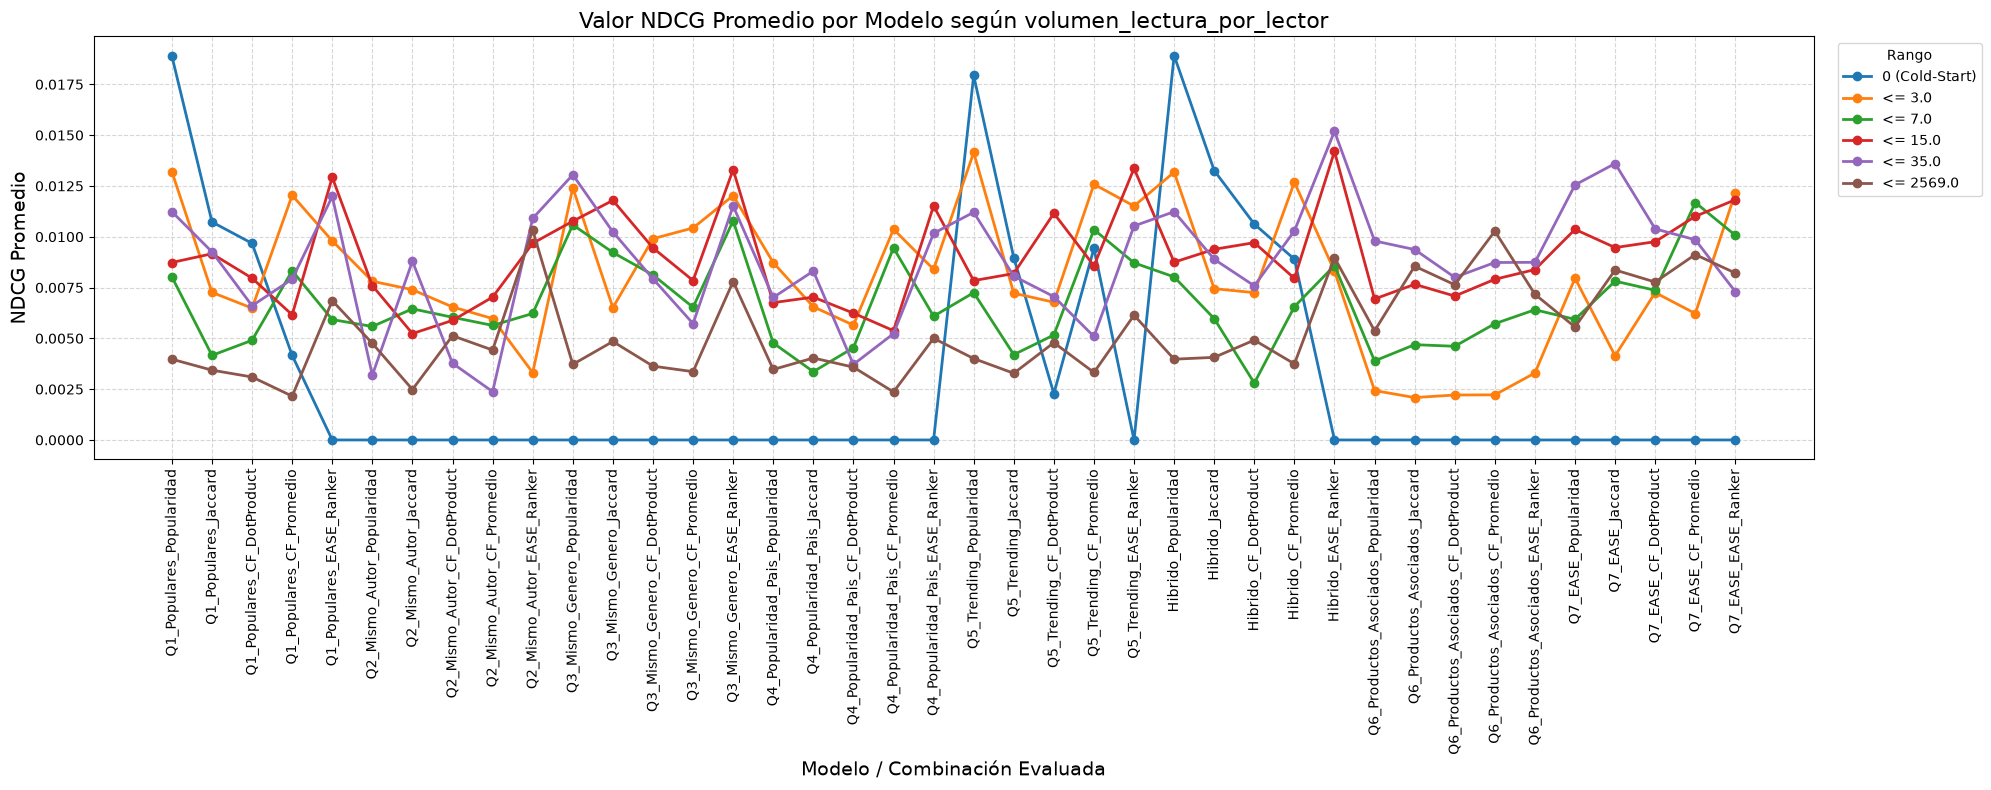

In [16]:
import matplotlib.pyplot as plt
caracteristica_evaluada = "volumen_lectura_por_lector"

# 1. Quitamos la columna de cantidad para graficar solo las métricas
df_plot = states[caracteristica_evaluada].drop(columns=['cantidad_lectores'])

df_plot.columns = [c.replace('ndcg_', '').replace('_mean', '') for c in df_plot.columns]

# 2. Transponemos el DataFrame (.T)
# Ahora los modelos son las filas (eje X) y los rangos de volumen son las columnas (líneas)
df_plot_t = df_plot.T

# 3. Armamos el gráfico
# Usamos figsize=(20, 8) para que sea ancho, ya que tienes más de 40 elementos en el eje X
plt.figure(figsize=(20, 8))

# Graficamos. 'marker="o"' pone un puntito en cada valor para ver bien dónde cae.
df_plot_t.plot(ax=plt.gca(), marker='o', linewidth=2)

# Configuraciones de etiquetas y título
plt.title(f'Valor NDCG Promedio por Modelo según {caracteristica_evaluada}', fontsize=16)
plt.xlabel('Modelo / Combinación Evaluada', fontsize=14)
plt.ylabel('NDCG Promedio', fontsize=14)

# Configuramos el eje X para que muestre todos los nombres y los rotamos 90 grados
plt.xticks(ticks=range(len(df_plot_t.index)), labels=df_plot_t.index, rotation=90)

# Movemos la leyenda afuera del gráfico para que no tape las curvas
plt.legend(title=f'Rango', bbox_to_anchor=(1.01, 1), loc='upper left')

plt.grid(True, linestyle='--', alpha=0.5)

# tight_layout() evita que los textos muy largos (eje x) queden cortados en la imagen final
plt.tight_layout() 

# Mostramos el gráfico
plt.show()

# 

In [1]:
import pandas as pd
results = pd.read_csv('outputs/resultados/resultados_experimentos.csv')
results

,Retrieval,Ranker,Recall_Retrieval_Promedio,NDCG@20_Promedio,Tiempo_Segundos
0,Q1_Populares,Popularidad,0.039417,0.010018,1.84
1,Q1_Populares,Jaccard,0.039417,0.007020,2.06
2,Q1_Populares,CF_DotProduct,0.039417,0.006155,2.92
3,Q1_Populares,CF_Promedio,0.039417,0.007142,6.20
4,Q1_Populares,EASE_Ranker,0.039417,0.008625,10.35
5,Q2_Mismo_Autor,Popularidad,0.015522,0.005294,2.43
6,Q2_Mismo_Autor,Jaccard,0.015522,0.005554,2.51
7,Q2_Mismo_Autor,CF_DotProduct,0.015522,0.004997,3.00
8,Q2_Mismo_Autor,CF_Promedio,0.015522,0.004627,5.18
9,Q2_Mismo_Autor,EASE_Ranker,0.015522,0.007244,11.72


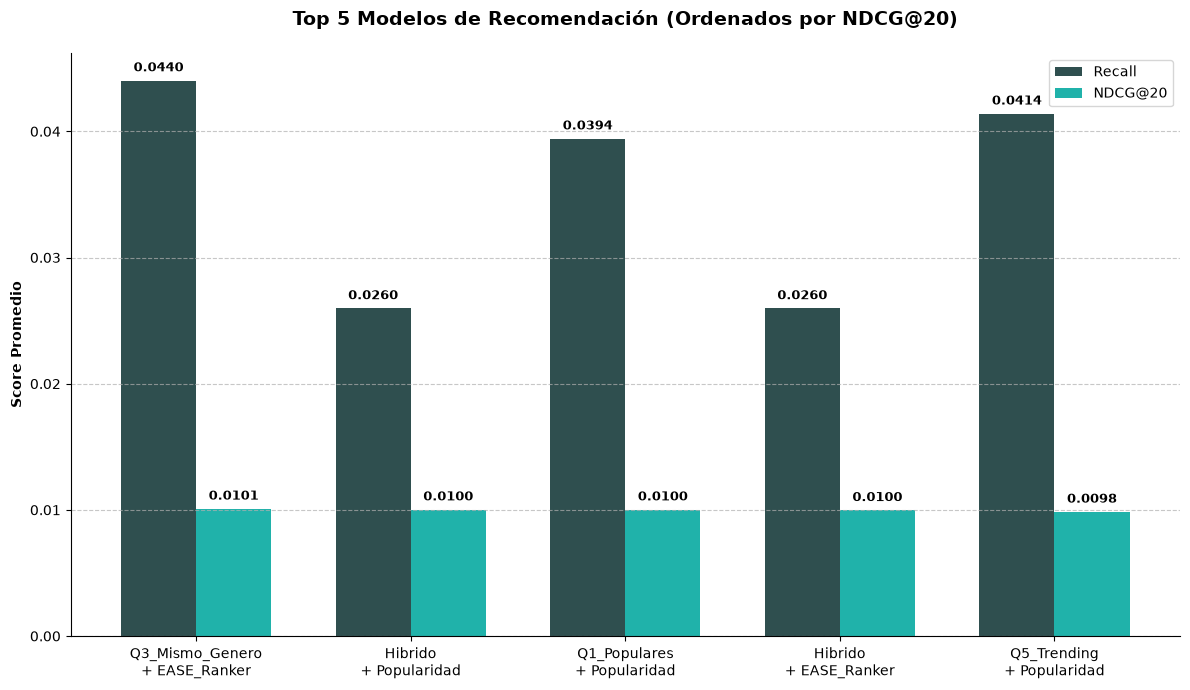

In [2]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Crear la etiqueta combinada para el eje X
results['Combinacion'] = results['Retrieval'] + '\n+ ' + results['Ranker']

# 2. Filtrar el top 5 por NDCG@20
top_5 = results.sort_values(by='NDCG@20_Promedio', ascending=False).head(5)

# 3. Configurar el gráfico
x = np.arange(len(top_5))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 7))

# Limpiar bordes y agregar grilla
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.yaxis.grid(True, linestyle='--', alpha=0.7)

# 4. Crear las barras de Recall y NDCG
rects1 = ax.bar(x - width/2, top_5['Recall_Retrieval_Promedio'], width, label='Recall', color='#2F4F4F')
rects2 = ax.bar(x + width/2, top_5['NDCG@20_Promedio'], width, label='NDCG@20', color='#20B2AA')

# 5. Agregar los valores exactos arriba de cada barra
for p in ax.patches:
    ax.annotate(f"{p.get_height():.4f}", 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', 
                xytext=(0, 9), 
                textcoords='offset points',
                fontsize=9, weight='bold')

# 6. Formato final
ax.set_ylabel('Score Promedio', fontweight='bold')
ax.set_title('Top 5 Modelos de Recomendación (Ordenados por NDCG@20)', pad=20, fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(top_5['Combinacion'], rotation=0, fontsize=10)
ax.legend(loc='upper right')

plt.tight_layout()
plt.show()